# Three-body capture and binary-planet formation

This notebook combines Captus's direct three-body scattering API with a published equal-mass hard-binary formation-rate fit and a PCAT posterior over the rate normalization. All counts below are synthetic examples, not measurements of a star cluster or planetary population.

## 1. Clone Captus and set up the environment

From the workspace parent, a first-time checkout and environment setup look like this:

```bash
git clone https://github.com/AstroMusers/captus.git astromusers/captus
cd astromusers/captus
python -m venv .venv
source .venv/bin/activate
python -m pip install -e ".[inference,dev]"
```

The remaining cells assume the notebook kernel runs from this Captus checkout with the `inference` extra installed.

In [1]:
%%bash
set -euo pipefail
if git rev-parse --show-toplevel >/dev/null 2>&1; then
    echo "Using the existing Captus checkout."
else
    git clone https://github.com/AstroMusers/captus.git captus
    echo "Cloned Captus."
fi
# For a separate environment, run these once from the repository root:
# python -m venv .venv
# source .venv/bin/activate
# python -m pip install -e ".[inference,dev]"

Using the existing Captus checkout.


In [2]:
from importlib.metadata import PackageNotFoundError, version
from importlib.util import find_spec
from pathlib import Path
import platform
import sys

repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
if not (repo_root / "pyproject.toml").is_file():
    raise RuntimeError("Run this notebook from the Captus checkout or its notebooks directory.")
sys.path.insert(0, str(repo_root / "src"))
local_pcat_root = repo_root.parents[1] / "tansudaylan" / "pcat"
if find_spec("pcat") is None and (local_pcat_root / "pcat").is_dir():
    sys.path.insert(0, str(local_pcat_root))

print(f"Python {platform.python_version()}")
for package_name in ("captus", "numpy", "astropy", "rebound", "pcat"):
    try:
        print(f"{package_name}: {version(package_name)}")
    except PackageNotFoundError:
        print(f"{package_name}: not installed")
print("Reproducible seed for the encounter example: 42")

Python 3.14.7
captus: 1.1.1.dev2+gd70becda7.d20261014
numpy: 2.5.3
astropy: 8.0.1
rebound: 5.2.2
pcat: 0.1.0
Reproducible seed for the encounter example: 42


## 2. Inspect inference and verify PCAT integration

Captus's existing PBH pipeline performs Monte Carlo encounter sampling and REBOUND evolution. This notebook adds a separate fixed-dimensional PCAT model for the binary-formation rate normalization. The scan below inspects Python imports and the project's declared inference extra without reading stored notebook outputs.

In [3]:
import ast
import tomllib

source_root = repo_root / "src" / "captus"
pcat_import_sites = []
for source_path in source_root.rglob("*.py"):
    source_tree = ast.parse(source_path.read_text(encoding="utf-8"))
    for node in ast.walk(source_tree):
        if isinstance(node, ast.Import):
            if any(alias.name == "pcat" or alias.name.startswith("pcat.") for alias in node.names):
                pcat_import_sites.append(source_path.relative_to(repo_root))
        elif isinstance(node, ast.ImportFrom) and node.module:
            if node.module == "pcat" or node.module.startswith("pcat."):
                pcat_import_sites.append(source_path.relative_to(repo_root))

project_config = tomllib.loads((repo_root / "pyproject.toml").read_text(encoding="utf-8"))
pcat_extra = project_config["project"]["optional-dependencies"].get("inference", [])
print(f"PCAT import sites: {pcat_import_sites}")
print(f"Declared PCAT inference extra: {pcat_extra}")
if not pcat_import_sites or not any(dependency.startswith("pcat @") for dependency in pcat_extra):
    raise RuntimeError("PCAT inference is not wired into Captus.")

PCAT import sites: [PosixPath('src/captus/three_body_capture/planetary_binary.py')]
Declared PCAT inference extra: ['pcat @ git+https://github.com/tansudaylan/pcat.git']


## 3. Minimal PCAT inference example

For equal-mass, initially unbound planets with a shared isotropic Maxwellian velocity distribution, the hard-binary fit from Atallah et al. (2024, arXiv:2402.12429) is

$$\Gamma(<a_{\\max}) = 0.081\,G^5m^5n^3\\sigma^{-9}\\left(\\frac{a_{\\max}}{a_{\\rm fs}}\\right)^3\\sqrt{\\chi_1}, \\qquad a_{\\rm fs}=\\frac{Gm}{3\\sigma^2}.$$

The rate counts all binary pairings and is limited to $a_{\\max}\\leq a_{\\rm fs}$ and $\\chi_1\\geq10$. Here $n$ is the number density of each of the three planet populations. The PCAT fit below uses a synthetic Poisson count to infer a multiplicative rate normalization.

Hard-binary scale: 3.14 AU
Rate density: 1.5525536840598618e-11 1 / (yr pc3)


Synthetic observed count: 18
Baseline expected count: 15.5
PCAT normalization median and 90% interval: 1.2 [0.818, 1.68]


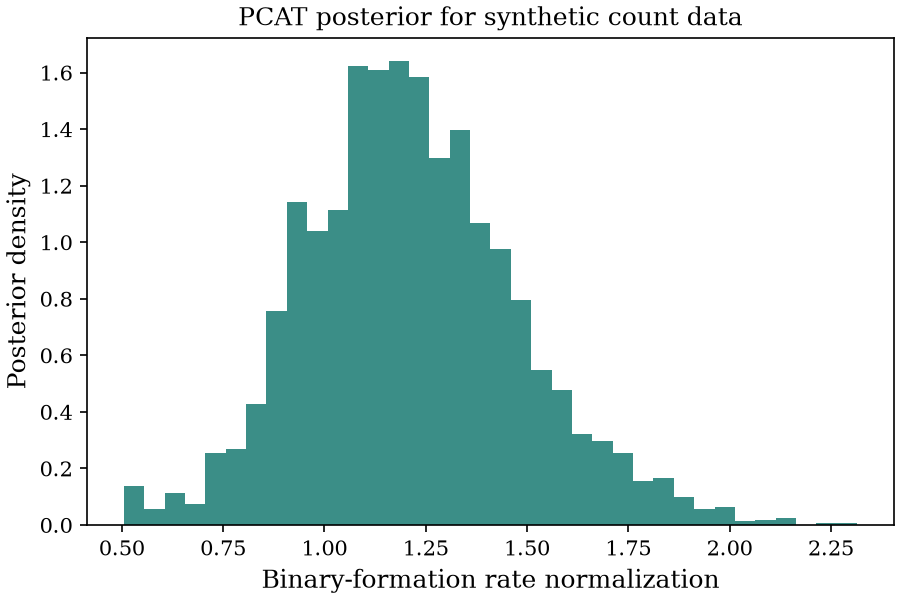

In [4]:
import contextlib
import io

import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from IPython.display import Image, display

from captus.three_body_capture import (
    compute_binary_planet_formation_rate,
    infer_binary_planet_rate_normalization_pcat,
)

planet_mass = 1.0 * u.M_jup
planet_number_density = 1.0e6 / u.pc**3
velocity_dispersion = 0.3 * u.km / u.s
rate_model = compute_binary_planet_formation_rate(
    planet_mass,
    planet_number_density,
    velocity_dispersion,
    chi1=10.0,
)
print(f"Hard-binary scale: {rate_model['hard_semimajor_axis'].to(u.au):.3g}")
print(
    "Rate density:",
    rate_model["formation_rate_density"].to(1 / (u.pc**3 * u.yr)),
)

cluster_volume = 1000.0 * u.pc**3
evolution_time = 1.0 * u.Gyr
synthetic_observed_count = 18
pcat_log = io.StringIO()
with contextlib.redirect_stdout(pcat_log):
    rate_posterior = infer_binary_planet_rate_normalization_pcat(
        rate_model["formation_rate_density"],
        cluster_volume,
        evolution_time,
        observed_count=synthetic_observed_count,
        normalization_bounds=(0.01, 5.0),
        chain_count=4,
        sample_count=800,
        burn_count=400,
        seed=42,
    )
normalization_samples = rate_posterior["normalization_samples"].ravel()
normalization_interval = np.quantile(normalization_samples, [0.05, 0.5, 0.95])
print(f"Synthetic observed count: {synthetic_observed_count}")
print(f"Baseline expected count: {rate_posterior['base_expected_count']:.3g}")
print(
    "PCAT normalization median and 90% interval: "
    f"{normalization_interval[1]:.3g} "
    f"[{normalization_interval[0]:.3g}, {normalization_interval[2]:.3g}]"
)

with plt.rc_context({"text.usetex": False}):
    figure, axis = plt.subplots(figsize=(6, 4), constrained_layout=True)
    axis.hist(normalization_samples, bins=36, density=True, color="#187A72", alpha=0.85)
    axis.set_xlabel("Binary-formation rate normalization")
    axis.set_ylabel("Posterior density")
    axis.set_title("PCAT posterior for synthetic count data")
    axis.grid(False)
    image_buffer = io.BytesIO()
    figure.savefig(image_buffer, format="png", dpi=150)
    display(Image(data=image_buffer.getvalue()))
    plt.close(figure)

## 4. Define the three-body encounter API

`PlanetBody` stores each mass and optional physical radius. `ThreeBodyEncounter` packages the three initial position and velocity vectors, total integration time, checkpoint count, and binary–single separation threshold. `BinaryCaptureResult` records the final classification, orbital elements when a binary escapes, and relative energy and angular-momentum errors. Positions, velocities, masses, and times are Astropy quantities.

In [5]:
from captus.three_body_capture import (
    BinaryCaptureResult,
    PlanetBody,
    ThreeBodyEncounter,
    sample_equal_mass_unbound_encounter,
    simulate_three_body_capture,
)

encounter = sample_equal_mass_unbound_encounter(
    planet_mass,
    velocity_dispersion,
    chi1=10.0,
    seed=29,
    checkpoints=20,
    escape_separation_factor=5.0,
)
print(f"Encounter type: {type(encounter).__name__}")
print(f"Bodies: {[body.name for body in encounter.bodies]}")
print(f"Initial positions shape: {encounter.positions.shape}")
print(f"Initial velocities shape: {encounter.velocities.shape}")
print(f"Integration window: {encounter.integration_time.to(u.yr):.3g}")
print(f"Interaction radius: {encounter.interaction_radius.to(u.au):.3g}")

Encounter type: ThreeBodyEncounter
Bodies: ['planet_1', 'planet_2', 'planet_3']
Initial positions shape: (3, 3)
Initial velocities shape: (3, 3)
Integration window: 1.03e+05 yr
Interaction radius: 62.7 AU


## 5. Integrate the Newtonian three-body encounter

REBOUND's adaptive IAS15 integrator advances the three planets in AU, years, and solar masses. At each checkpoint, Captus looks for a negative-energy pair and a positive-energy third planet moving outward beyond the hierarchy threshold. The run also records total-energy and angular-momentum drift. A run is marked `unresolved` when the configured integration window ends before a stable binary–single outcome can be identified. Such a run is not counted as a capture.

In [6]:
capture_outcome = simulate_three_body_capture(encounter)
print(f"Outcome: {capture_outcome.status}")
print(f"Binary captured: {capture_outcome.captured}")
print(f"Integration time: {capture_outcome.integration_time.to(u.yr):.3g}")
print(f"Relative energy error: {capture_outcome.energy_error:.3e}")
print(f"Relative angular-momentum error: {capture_outcome.angular_momentum_error:.3e}")
if capture_outcome.captured:
    print(f"Binary semimajor axis: {capture_outcome.semi_major_axis.to(u.au):.3g}")
    print(f"Binary eccentricity: {capture_outcome.eccentricity:.3f}")

Outcome: binary_capture
Binary captured: True
Integration time: 7.74e+04 yr
Relative energy error: 8.183e-15
Relative angular-momentum error: 5.090e-15
Binary semimajor axis: 280 AU
Binary eccentricity: 0.917


## 6. Connect capture outcomes to inference

The CLI exposes mass, velocity dispersion, interaction scale, random seed, checkpoint count, and escape-separation threshold. Each run emits a JSON record with unit-labeled orbital and conservation fields. The rate posterior above is intentionally normalized with a separate synthetic count model; an unresolved scattering is not silently treated as a failed formation event, and the rate fit does not replace selection, collision, or disruption modeling.

```bash
PYTHONPATH=src captus-binary-capture --mass-mjup 1 --velocity-dispersion-kms 0.3 --chi1 10 --seed 29 --checkpoints 20 --escape-separation-factor 5
```

In [7]:
import json

serialized_outcome = capture_outcome.to_dict()
print(json.dumps(serialized_outcome, indent=2))
print("Posterior sampler:", rate_posterior["sampler"])
print("Posterior expected-count sample shape:", rate_posterior["expected_formation_count_samples"].shape)

{
  "status": "binary_capture",
  "captured": true,
  "binary_indices": [
    0,
    1
  ],
  "single_index": 2,
  "semi_major_axis_au": 280.4060199326438,
  "eccentricity": 0.9173218398791219,
  "integration_time_yr": 77375.92229179245,
  "energy_error": 8.182715170002945e-15,
  "angular_momentum_error": 5.090097975981387e-15,
  "initial_energy_j": 5.20360343920744e+31,
  "final_energy_j": 5.203603439207398e+31
}
Posterior sampler: PCAT
Posterior expected-count sample shape: (4, 800)


## 7. Run the binary-capture and PCAT regression tests

The tests cover rate scalings and units, rejected hard-binary inputs, seeded unbound initial conditions, binary–single classification, conservation diagnostics, and the PCAT callback boundary.

In [8]:
import os
import subprocess

test_environment = os.environ.copy()
test_environment["PYTHONPATH"] = str(repo_root / "src")
test_run = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_planetary_binary.py"],
    cwd=repo_root,
    env=test_environment,
    capture_output=True,
    text=True,
)
print(test_run.stdout)
print(f"Focused test return code: {test_run.returncode}")
if test_run.returncode != 0:
    raise RuntimeError("The binary-planet feature tests failed.")

.........                                                                [100%]
9 passed in 1.34s

Focused test return code: 0


## 8. Run Mission Control

When this notebook is inside the full workspace, the last cell runs the repository Mission Control script and captures its output. In a standalone Captus clone, that workspace-only step is skipped. The cell reports only the return code and number of generated write operations, not machine-specific paths.

In [9]:
workspace_root = repo_root.parents[1]
mission_control_script = (
    workspace_root / "tansudaylan" / "docs" / "MissionControl" / "MissionControl.py"
)
if mission_control_script.is_file():
    mission_environment = os.environ.copy()
    mission_environment["DOCS_PATH"] = str(mission_control_script.parents[1])
    mission_run = subprocess.run(
        [sys.executable, str(mission_control_script)],
        cwd=workspace_root,
        env=mission_environment,
        capture_output=True,
        text=True,
    )
    write_operations = sum(
        line.startswith("Writing to ") for line in mission_run.stdout.splitlines()
    )
    print(f"Mission Control return code: {mission_run.returncode}")
    print(f"Captured write operations: {write_operations}")
    if mission_run.returncode != 0:
        raise RuntimeError("Mission Control failed.")
else:
    print("Mission Control is unavailable in this standalone checkout.")

Mission Control return code: 0
Captured write operations: 19
